# Fase 1 - Modelo predictivo
## Predicción del precio de vehículos usados en UAE

**Estudiantes:**
- Andrés Felipe Borja Úsuga
- Juan Jerónimo Echeverry Chica
- Cristian Mateo Sepúlveda Ochoa

**Curso:** Modelos y Simulación de Sistemas I  
**Proyecto:** UAE Used Cars Analysis  
**Tipo de problema:** Regresión  
**Variable objetivo:** `Price`

### Objetivo
Construir y evaluar un modelo de Machine Learning capaz de predecir el precio de un vehículo usado a partir de sus características.

### Qué debe demostrar este notebook
1. Exploración y preparación de los datos.
2. Desarrollo/adaptación de modelos predictivos.
3. Evaluación mediante métricas de regresión.
4. Prevención de fuga de información (*data leakage*).
5. Almacenamiento del modelo final.


## 0. Idea general del proceso

El flujo que seguiremos será:

**Datos → exploración → limpieza básica → separación entrenamiento/prueba → preprocesamiento → comparación de modelos → evaluación final → guardar modelo**

La separación entre entrenamiento y prueba se realiza **antes de ajustar imputadores, codificadores o modelos**, para evitar que información del conjunto de prueba influya en el entrenamiento.


In [ ]:
!pip install pandas numpy matplotlib scikit-learn joblib
!pip install --upgrade pip
!pip install rlxutils --no-cache-dir

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for rlxutils: filename=rlxutils-0.1.10-py3-none-any.whl size=11146 sha256=00a3fe08affc26028d8cc2de7a76b8dd18e607a42ec1b341a4a4a85636409285
  Stored in directory: /tmp/pip-ephem-wheel-cache-e1pb68he/wheels/af/5e/e9/0d79a77bc3696fc2ca1ce403d14e73277c01f95d7f0ee38b26
Successfully built rlxutils


## 1. Cargar el dataset

El dataset lo tengo alojado en mi Drive, no es necesario subirlo nuevamente, solo es cuestión de ejecutar la celda

In [ ]:
from pathlib import Path
import pandas as pd

FILE_ID = "1EeDYF52dSmTX1lM8OOt55qjilf7yNvPi"
DATA_URL = f"https://drive.google.com/uc?export=download&id={FILE_ID}"

df = pd.read_csv(DATA_URL)

print(f"Archivo cargado desde Drive (ID: {FILE_ID})")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
df.head()

Archivo cargado desde Drive (ID: 1EeDYF52dSmTX1lM8OOt55qjilf7yNvPi)
Filas: 10,000
Columnas: 12


,Make,Model,Year,Price,Mileage,Body Type,Cylinders,Transmission,Fuel Type,Color,Location,Description
0,toyota,camry,2016,47819,156500,Sedan,4,Automatic Transmission,Gasoline,Black,Dubai,"2016 toyota camry with Rear camera, Leather se..."
1,kia,sorento,2013,61250,169543,SUV,4,Automatic Transmission,Gasoline,Grey,Abu Dhabi,"2013 kia sorento with Sunroof, Adaptive cruise..."
2,mini,cooper,2023,31861,221583,Soft Top Convertible,4,Automatic Transmission,Gasoline,Grey,Dubai,"2023 mini cooper with Adaptive cruise control,..."
3,nissan,altima,2016,110322,69754,Sedan,4,Automatic Transmission,Gasoline,Red,Dubai,"2016 nissan altima with Rear camera, Adaptive ..."
4,toyota,land-cruiser-76-series,2020,139994,71399,Pick Up Truck,4,Manual Transmission,Gasoline,White,Dubai,2020 toyota land-cruiser-76-series with Adapti...


## 2. Verificar que estén las columnas esperadas

Según la propuesta de nuestro equipo, trabajaremos inicialmente con **11 variables predictoras** y una variable objetivo (`Price`).

Esta comprobación sirve para detectar inmediatamente si se cargó un archivo equivocado o si el dataset cambió.


In [ ]:
expected_predictors = [
    "Make",
    "Model",
    "Year",
    "Mileage",
    "Body Type",
    "Cylinders",
    "Transmission",
    "Fuel Type",
    "Color",
    "Location",
    "Description",
]

target = "Price"

expected_columns = expected_predictors + [target]
missing_columns = [c for c in expected_columns if c not in df.columns]

print("Columnas encontradas:")
print(df.columns.tolist())

if missing_columns:
    raise ValueError(
        f"Faltan columnas esperadas en el CSV: {missing_columns}"
    )

print("\n El dataset contiene todas las columnas esperadas.")

Columnas encontradas:
['Make', 'Model', 'Year', 'Price', 'Mileage', 'Body Type', 'Cylinders', 'Transmission', 'Fuel Type', 'Color', 'Location', 'Description']

 El dataset contiene todas las columnas esperadas.


## 3. Exploración inicial (Exploratory Data Analysis)

Aquí responderemos preguntas sencillas:

- ¿Cuántas observaciones existen?
- ¿Qué tipo de dato tiene cada columna?
- ¿Hay valores faltantes?
- ¿Hay filas duplicadas?
- ¿Cómo se distribuye el precio?
- ¿Cuáles son las marcas más frecuentes?

In [ ]:
print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nPrimeras filas:")
display(df.head())

Dimensiones del dataset: (10000, 12)

Tipos de datos:


,tipo
Make,object
Model,object
Year,int64
Price,int64
Mileage,int64
Body Type,object
Cylinders,object
Transmission,object
Fuel Type,object
Color,object



Primeras filas:


,Make,Model,Year,Price,Mileage,Body Type,Cylinders,Transmission,Fuel Type,Color,Location,Description
0,toyota,camry,2016,47819,156500,Sedan,4,Automatic Transmission,Gasoline,Black,Dubai,"2016 toyota camry with Rear camera, Leather se..."
1,kia,sorento,2013,61250,169543,SUV,4,Automatic Transmission,Gasoline,Grey,Abu Dhabi,"2013 kia sorento with Sunroof, Adaptive cruise..."
2,mini,cooper,2023,31861,221583,Soft Top Convertible,4,Automatic Transmission,Gasoline,Grey,Dubai,"2023 mini cooper with Adaptive cruise control,..."
3,nissan,altima,2016,110322,69754,Sedan,4,Automatic Transmission,Gasoline,Red,Dubai,"2016 nissan altima with Rear camera, Adaptive ..."
4,toyota,land-cruiser-76-series,2020,139994,71399,Pick Up Truck,4,Manual Transmission,Gasoline,White,Dubai,2020 toyota land-cruiser-76-series with Adapti...


In [ ]:
# Información general de las columnas
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Make          10000 non-null  object
 1   Model         10000 non-null  object
 2   Year          10000 non-null  int64 
 3   Price         10000 non-null  int64 
 4   Mileage       10000 non-null  int64 
 5   Body Type     10000 non-null  object
 6   Cylinders     9895 non-null   object
 7   Transmission  10000 non-null  object
 8   Fuel Type     10000 non-null  object
 9   Color         10000 non-null  object
 10  Location      10000 non-null  object
 11  Description   10000 non-null  object
dtypes: int64(3), object(9)
memory usage: 937.6+ KB


In [ ]:
# Estadísticas descriptivas de variables numéricas
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
Year,10000.0,2014.4728,5.790839,2005.0,2009.0,2014.0,2019.00,2024.0
Price,10000.0,245234.5079,470977.346779,7183.0,50352.5,102766.0,231248.00,14686975.0
Mileage,10000.0,155161.8717,83681.858983,10006.0,82904.0,154370.5,227551.25,299996.0


### 3.1 Valores faltantes

Primero revisamos los `NaN` que pandas reconoce directamente.

Después analizaremos `Cylinders` con más cuidado porque puede contener textos como `Unknown`, que no siempre aparecen como `NaN` al leer el CSV.


In [ ]:
missing = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(3)
}).sort_values("faltantes", ascending=False)

missing

,faltantes,porcentaje
Cylinders,105,1.05
Make,0,0.00
Year,0,0.00
Model,0,0.00
Price,0,0.00
Mileage,0,0.00
Body Type,0,0.00
Transmission,0,0.00
Fuel Type,0,0.00
Color,0,0.00


In [ ]:
# Inspección específica de Cylinders
print("Valores más frecuentes en Cylinders:")
display(df["Cylinders"].value_counts(dropna=False).head(20))

cylinders_numeric = pd.to_numeric(df["Cylinders"], errors="coerce")

n_missing_cylinders = cylinders_numeric.isna().sum()
pct_missing_cylinders = cylinders_numeric.isna().mean() * 100

print(f"\nRegistros de Cylinders faltantes/no convertibles: {n_missing_cylinders}")
print(f"Porcentaje: {pct_missing_cylinders:.3f}%")

Valores más frecuentes en Cylinders:


,count
Cylinders,
6,3420
8,3003
4,2929
12,340
NaN,105
3,53
5,52
Unknown,50
10,48



Registros de Cylinders faltantes/no convertibles: 155
Porcentaje: 1.550%


### ¿Qué significa `errors="coerce"`?

`Cylinders` debería representar un número de cilindros. Si aparece un valor como `Unknown`, pandas no puede convertirlo directamente a número.

Con:

```python
pd.to_numeric(..., errors="coerce")
```

los valores no convertibles pasan a ser `NaN`.

Esto **no utiliza información de `Price`** y por tanto no constituye fuga de información.


### 3.2 Duplicados

Una fila duplicada podría hacer que el mismo ejemplo aparezca tanto en entrenamiento como en prueba.

Para empezar, contaremos los duplicados exactos.

In [ ]:
duplicados = df.duplicated().sum()
print(f"Filas duplicadas exactas: {duplicados}")

Filas duplicadas exactas: 0


## 4. Exploración de la variable objetivo: `Price`

`Price` es lo que el modelo intentará predecir.

En esta sección no vamos a eliminar valores extremos automáticamente. Primero los observamos y documentamos.

In [ ]:
# Convertimos Price a numérico por seguridad
price_numeric = pd.to_numeric(df["Price"], errors="coerce")

print(price_numeric.describe())
print(f"Valores de Price no numéricos o faltantes: {price_numeric.isna().sum()}")

count    1.000000e+04
mean     2.452345e+05
std      4.709773e+05
min      7.183000e+03
25%      5.035250e+04
50%      1.027660e+05
75%      2.312480e+05
max      1.468698e+07
Name: Price, dtype: float64
Valores de Price no numéricos o faltantes: 0


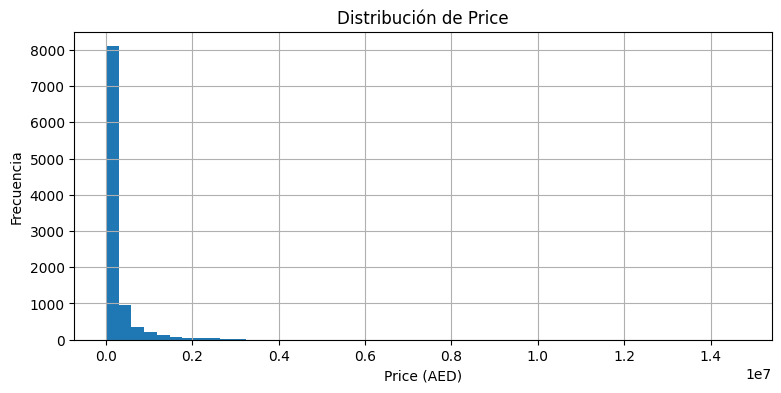

In [ ]:
plt.figure(figsize=(9, 4))
price_numeric.dropna().hist(bins=50)
plt.title("Distribución de Price")
plt.xlabel("Price (AED)")
plt.ylabel("Frecuencia")
plt.show()

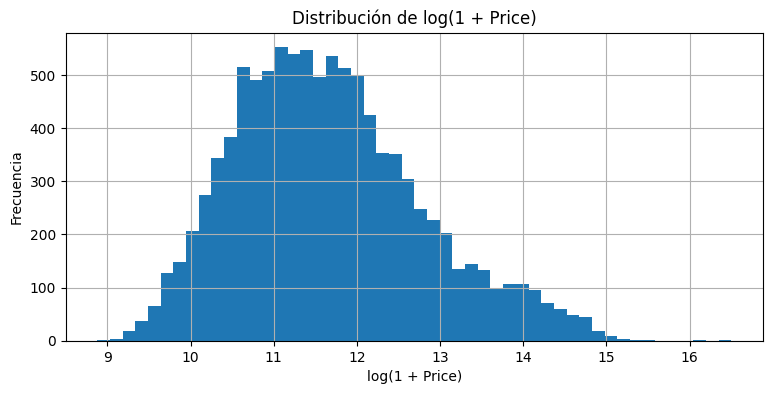

In [ ]:
# La escala logarítmica nos ayuda a visualizar una distribución muy sesgada
plt.figure(figsize=(9, 4))
np.log1p(price_numeric.dropna()).hist(bins=50)
plt.title("Distribución de log(1 + Price)")
plt.xlabel("log(1 + Price)")
plt.ylabel("Frecuencia")
plt.show()

### Interpretación

La distribución de `Price` presenta asimetría hacia la derecha, debido a la presencia de vehículos de alto valor. Por esta razón, además de R², se utilizarán MAE y RMSE para evaluar los errores de predicción.


## 5. Exploración de variables predictoras


,cantidad
Make,
mercedes-benz,1486
nissan,925
toyota,893
bmw,698
ford,541
land-rover,538
porsche,450
audi,397
jeep,345


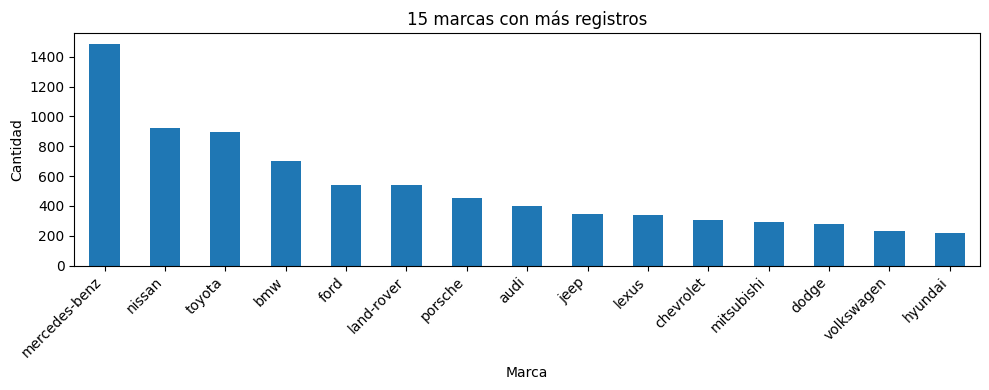

In [ ]:
# Marcas con más registros
display(df["Make"].value_counts().head(15).to_frame("cantidad"))

plt.figure(figsize=(10, 4))
df["Make"].value_counts().head(15).plot(kind="bar")
plt.title("15 marcas con más registros")
plt.xlabel("Marca")
plt.ylabel("Cantidad")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,precio_mediano
Make,
rolls-royce,1960280.0
lamborghini,1527980.0
maybach,1106594.0
ferrari,945715.0
mclaren,689130.0
aston-martin,489388.0
bentley,403997.0
tesla,242213.0
porsche,231662.0


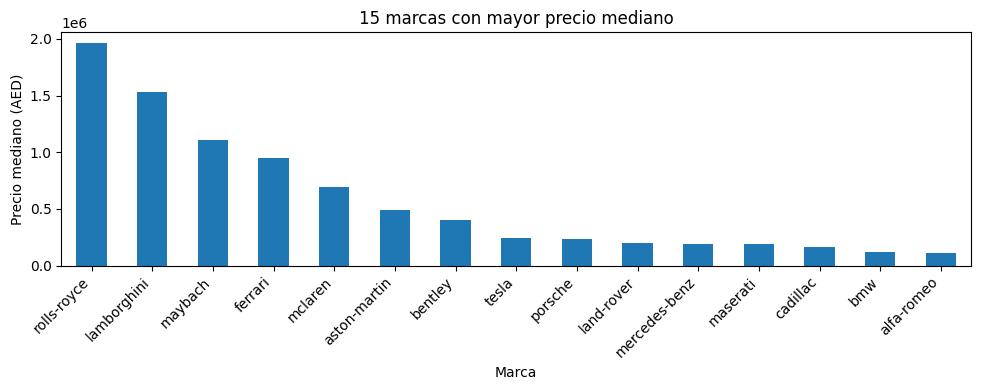

In [ ]:
# Precio mediano por marca (solo marcas con al menos 20 registros)
tmp = df.copy()
tmp["Price"] = pd.to_numeric(tmp["Price"], errors="coerce")

counts = tmp["Make"].value_counts()
valid_makes = counts[counts >= 20].index

median_price_by_make = (
    tmp[tmp["Make"].isin(valid_makes)]
    .groupby("Make")["Price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

display(median_price_by_make.to_frame("precio_mediano"))

plt.figure(figsize=(10, 4))
median_price_by_make.plot(kind="bar")
plt.title("15 marcas con mayor precio mediano")
plt.xlabel("Marca")
plt.ylabel("Precio mediano (AED)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

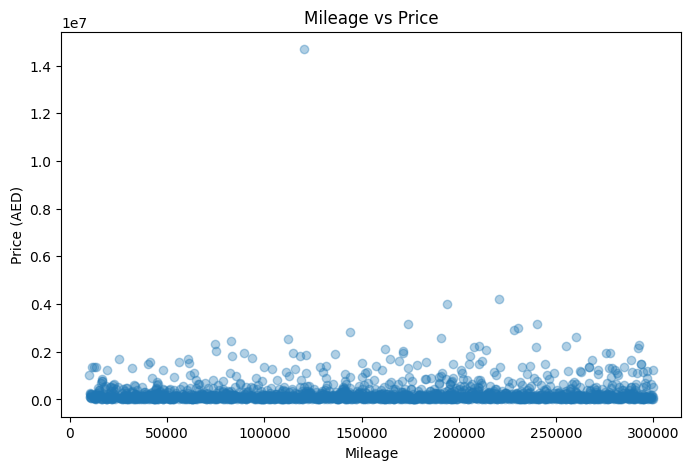

In [ ]:
# Relación entre kilometraje y precio
tmp_plot = df[["Mileage", "Price"]].copy()
tmp_plot["Mileage"] = pd.to_numeric(tmp_plot["Mileage"], errors="coerce")
tmp_plot["Price"] = pd.to_numeric(tmp_plot["Price"], errors="coerce")
tmp_plot = tmp_plot.dropna()

# Muestreo para mantener la gráfica legible
sample = tmp_plot.sample(min(2000, len(tmp_plot)), random_state=RANDOM_STATE)

plt.figure(figsize=(8, 5))
plt.scatter(sample["Mileage"], sample["Price"], alpha=0.35)
plt.title("Mileage vs Price")
plt.xlabel("Mileage")
plt.ylabel("Price (AED)")
plt.show()

## 6. Limpieza básica y definición de variables

Realizaremos únicamente transformaciones determinísticas antes de dividir los datos:

- Convertir `Price` a número.
- Convertir `Cylinders` a número, transformando valores no utilizables en `NaN`.
- Reemplazar descripciones faltantes por una cadena vacía.
- Eliminar filas cuyo `Price` no pueda utilizarse.
- Eliminar duplicados exactos.

La **imputación estadística**, el escalado y la codificación categórica se realizarán posteriormente dentro de un `Pipeline`, ajustado solo con datos de entrenamiento.


In [ ]:
df_model = df.copy()

# Transformaciones determinísticas
df_model["Price"] = pd.to_numeric(df_model["Price"], errors="coerce")
df_model["Cylinders"] = pd.to_numeric(df_model["Cylinders"], errors="coerce")
df_model["Description"] = df_model["Description"].fillna("").astype(str)

# El target no puede ser desconocido durante entrenamiento
before = len(df_model)
df_model = df_model.dropna(subset=["Price"]).copy()

# Evitamos que duplicados exactos puedan terminar en train y test
df_model = df_model.drop_duplicates().copy()

after = len(df_model)

print(f"Registros antes: {before:,}")
print(f"Registros después de limpieza básica: {after:,}")
print(f"Registros retirados: {before - after:,}")

Registros antes: 10,000
Registros después de limpieza básica: 10,000
Registros retirados: 0


## 7. Definir `X` e `y`

- `X`: variables que el modelo utilizará para realizar la predicción.
- `y`: variable que queremos predecir (`Price`).


In [ ]:
X = df_model[expected_predictors].copy()
y = df_model["Price"].copy()

print("X:", X.shape)
print("y:", y.shape)

X: (10000, 11)
y: (10000,)


## 8. Separar entrenamiento y prueba

Usaremos aproximadamente:

- **80 %** de los registros para entrenamiento.
- **20 %** para prueba final.

El conjunto de prueba permanecerá aislado hasta que hayamos seleccionado el modelo usando exclusivamente los datos de entrenamiento.

Esto reduce el riesgo de **fuga de información** y de sobreajustar nuestras decisiones al conjunto de prueba.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print(f"Entrenamiento: {len(X_train):,} registros")
print(f"Prueba:        {len(X_test):,} registros")

Entrenamiento: 8,000 registros
Prueba:        2,000 registros


## 9. Preprocesamiento

### Variables numéricas
- `Year`
- `Mileage`
- `Cylinders`

Tratamiento:
- valores faltantes → mediana;
- escalado estándar.

### Variables categóricas
- `Make`
- `Model`
- `Body Type`
- `Transmission`
- `Fuel Type`
- `Color`
- `Location`

Tratamiento:
- valores faltantes → categoría más frecuente;
- `OneHotEncoder` para convertir categorías a números.

### Texto
- `Description`

Tratamiento:
- `TF-IDF` limitado a un máximo de 300 características.

Todo se integra dentro de un `ColumnTransformer`, que posteriormente formará parte del `Pipeline` de cada modelo.


In [ ]:
numeric_features = [
    "Year",
    "Mileage",
    "Cylinders",
]

categorical_features = [
    "Make",
    "Model",
    "Body Type",
    "Transmission",
    "Fuel Type",
    "Color",
    "Location",
]

text_feature = "Description"

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

text_vectorizer = TfidfVectorizer(
    max_features=300,
    min_df=2,
    ngram_range=(1, 2),
    stop_words="english"
)

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("text", text_vectorizer, text_feature),
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Year', 'Mileage', 'Cylinders']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Make', 'Model', 'Body Type', 'Transmission',
                                  'Fuel Type', 'Color', 'Location']),
                                ('text',
                                 TfidfVectorizer(max_features=300, min_df=2,
                                                 ngram_range=(1, 2),
                                                 stop_words='english'),
                                 'Description')])

## 10. Prevención de fuga de información

En este proyecto se evita la fuga de información mediante las siguientes decisiones:

1. `Price` se usa exclusivamente como variable objetivo.
2. **No se crea ninguna variable predictora a partir de `Price`.**
3. El conjunto de prueba se separa antes de ajustar imputadores, escaladores, codificadores o modelos.
4. El preprocesamiento está dentro de un `Pipeline`, por lo que durante validación cada transformación se ajusta únicamente con los datos de entrenamiento correspondientes.
5. El conjunto de prueba final no se utiliza para escoger el modelo.

## 11. Modelos candidatos

Se compararán tres niveles:

1. **DummyRegressor**: baseline muy simple. Sirve para comprobar que nuestros modelos realmente aprendan algo.
2. **Ridge**: modelo lineal regularizado.
3. **RandomForestRegressor**: modelo no lineal basado en árboles.

La selección se realizará con **validación cruzada de 3 particiones usando solo el conjunto de entrenamiento**.


In [ ]:
candidate_models = {
    "DummyRegressor": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=10.0),
    "RandomForest": RandomForestRegressor(
        n_estimators=120,
        max_depth=20,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
}

candidate_models

{'DummyRegressor': DummyRegressor(strategy='median'),
 'Ridge': Ridge(alpha=10.0),
 'RandomForest': RandomForestRegressor(max_depth=20, min_samples_leaf=2, n_estimators=120,
                       n_jobs=-1, random_state=42)}

## 12. Comparación mediante validación cruzada

Para cada modelo calcularemos:

- **MAE**: error absoluto medio. Más pequeño es mejor.
- **R²**: proporción de variación explicada. En términos generales, más alto es mejor.

**La decisión de qué modelo escoger se basará principalmente en el MAE promedio de validación cruzada.**


In [ ]:
cv_results = []
trained_candidates = {}

for name, estimator in candidate_models.items():
    print(f"Evaluando: {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=3,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        n_jobs=1,
        return_train_score=False,
    )

    mean_mae = -scores["test_mae"].mean()
    std_mae = scores["test_mae"].std()
    mean_r2 = scores["test_r2"].mean()

    cv_results.append({
        "Modelo": name,
        "CV_MAE": mean_mae,
        "CV_MAE_std": std_mae,
        "CV_R2": mean_r2,
    })

results_df = (
    pd.DataFrame(cv_results)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

results_df

Evaluando: DummyRegressor...
Evaluando: Ridge...
Evaluando: RandomForest...


,Modelo,CV_MAE,CV_MAE_std,CV_R2
0,RandomForest,120017.079579,6635.164341,0.619516
1,Ridge,132912.672640,4390.371478,0.604791
2,DummyRegressor,191925.823873,12155.043043,-0.099581


### Interpretación

El modelo RandomForest obtuvo el menor MAE promedio durante validación cruzada y, por tanto, fue seleccionado para la evaluación final sobre el conjunto de prueba.

## 13. Seleccionar y entrenar el modelo final

El mejor modelo se escoge usando únicamente los resultados de validación cruzada sobre `X_train`.

Luego se ajusta con todo el conjunto de entrenamiento.


In [ ]:
best_name = results_df.iloc[0]["Modelo"]
best_estimator = candidate_models[best_name]

print(f"Modelo seleccionado por CV: {best_name}")

modelo_final = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_estimator),
])

modelo_final.fit(X_train, y_train)

print("Modelo final entrenado.")

Modelo seleccionado por CV: RandomForest
Modelo final entrenado.


## 14. Evaluación final sobre el conjunto de prueba

Ahora, utilizamos `X_test`.

Calcularemos:

- **MAE**: error absoluto medio.
- **RMSE**: penaliza con mayor fuerza errores grandes.
- **R²**: mide qué parte de la variación del precio logra explicar el modelo.

In [ ]:
y_pred = modelo_final.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

final_metrics = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Resultado": [mae, rmse, r2],
})

final_metrics

,Métrica,Resultado
0,MAE,118341.933082
1,RMSE,388796.190899
2,R²,0.423431


### Cómo interpretar las métricas

Después de ejecutar, escriban una conclusión con sus propios números.

Ejemplo:

> El modelo final obtuvo un MAE de ___ AED, lo que significa que, en promedio, la diferencia absoluta entre el precio real y la predicción fue de aproximadamente ___ AED. El RMSE fue ___ y el R² fue ___.

No deben inventar ni redondear excesivamente las cifras.


## 15. Visualización: precio real vs precio predicho


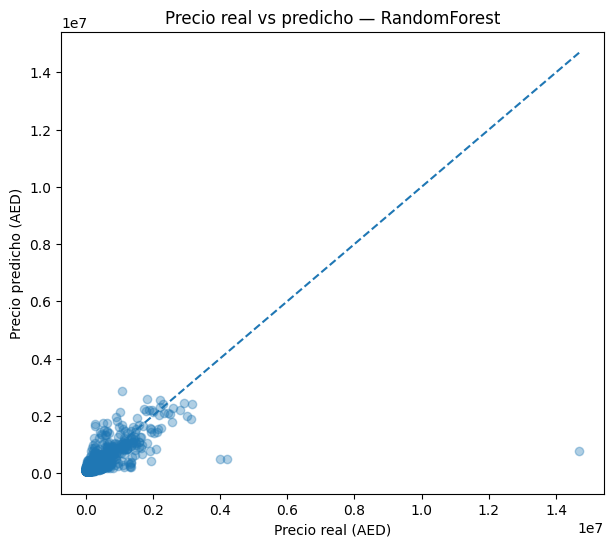

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.35)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Precio real (AED)")
plt.ylabel("Precio predicho (AED)")
plt.title(f"Precio real vs predicho — {best_name}")
plt.show()

## 16. Análisis de residuos


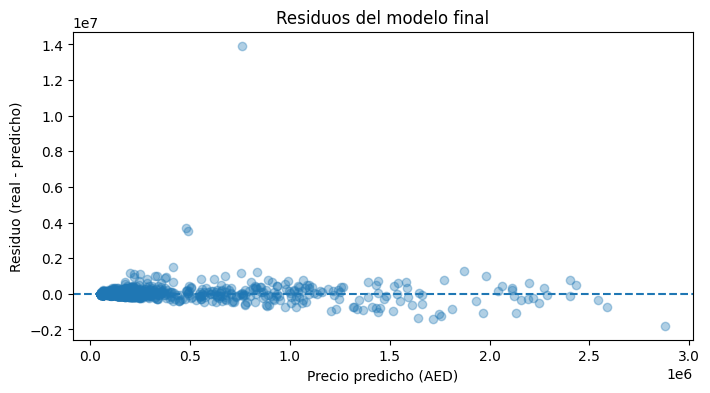

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Precio predicho (AED)")
plt.ylabel("Residuo (real - predicho)")
plt.title("Residuos del modelo final")
plt.show()

## 17. Guardar el modelo

El objeto que guardamos incluye:

- imputación;
- escalado;
- codificación;
- vectorización del texto;
- modelo predictivo.

Esto permitirá que en fases posteriores se pueda cargar **un solo archivo** para realizar predicciones.


In [ ]:
MODEL_PATH = Path("modelo_vehiculos_v1.joblib")

joblib.dump(modelo_final, MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH.resolve()}")
print(f"Tamaño: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

Modelo guardado en: /content/modelo_vehiculos_v1.joblib
Tamaño: 5.88 MB


:## 18. Comprobar que el modelo guardado funciona

No basta con crear el archivo: verificamos que pueda volver a cargarse y producir predicciones.

In [ ]:
modelo_cargado = joblib.load(MODEL_PATH)

predicciones_prueba = modelo_cargado.predict(X_test.iloc[:5])

comparison = pd.DataFrame({
    "Precio_real": y_test.iloc[:5].values,
    "Precio_predicho": predicciones_prueba,
})

comparison

,Precio_real,Precio_predicho
0,294670,178653.565645
1,21786,104850.143911
2,98031,105284.260863
3,257844,249451.710278
4,1220193,830683.284468


## 19. Conclusiones

Se desarrolló un modelo de regresión para predecir el precio de vehículos usados en UAE. Durante la exploración se identificó **una distribución muy asimétrica en la variable 'Price' hacia la derecha, la presencia de valores faltantes en 'Cylinders' y que no había filas duplicadas**. Los valores no utilizables de `Cylinders` fueron transformados a valores faltantes y posteriormente imputados dentro del pipeline. Se compararon **DummyRegressor, Ridge y RandomForestRegressor**. El modelo seleccionado mediante validación cruzada fue **RandomForest**. En el conjunto de prueba obtuvo MAE = **118341.93**, RMSE = **388796.19** y R² = **0.42**. Para evitar fuga de información, el conjunto de prueba permaneció separado durante el preprocesamiento y la selección del modelo. Finalmente, el pipeline completo fue almacenado en `modelo_vehiculos_v1.joblib`.

### README
### ¿Qué se hizo?

*   **Explorar y preparar los datos:**
    Se realizó una exploración inicial de los datos (EDA), donde se identificó una distribución asimétrica hacia la derecha de la variable `Price`, la presencia de valores faltantes en la columna `Cylinders` (los cuales fueron transformados a `NaN` y posteriormente imputados), y la ausencia de filas duplicadas. Se realizaron transformaciones determinísticas básicas y se separaron los conjuntos de entrenamiento y prueba antes de cualquier ajuste de preprocesadores.

*   **Desarrollar y comparar modelos predictivos:**
    Se compararon tres modelos de regresión: `DummyRegressor` (como baseline), `Ridge` y `RandomForestRegressor`. La selección del modelo se llevó a cabo mediante validación cruzada de 3 particiones utilizando exclusivamente el conjunto de entrenamiento.

*   **Evaluarlo:**
    El modelo seleccionado (`RandomForest`) fue evaluado en el conjunto de prueba final, obteniendo las siguientes métricas:
    *   **MAE:** 118341.93
    *   **RMSE:** 388796.19
    *   **R²:** 0.42
    Estas métricas indican un rendimiento aceptable, con un error absoluto medio de aproximadamente 118,341 AED.

*   **Evitar fuga de información:**
    Para prevenir la fuga de información, el conjunto de prueba se mantuvo completamente separado y aislado durante todo el proceso de preprocesamiento, selección y ajuste de modelos. Todas las transformaciones (imputación, escalado, codificación) se aplicaron dentro de un `Pipeline` ajustado únicamente con los datos de entrenamiento.

*   **Guardar el modelo:**
    El pipeline completo del modelo final, incluyendo todas las etapas de preprocesamiento y el estimador, fue serializado y guardado en el archivo `modelo_vehiculos_v1.joblib` para su posterior uso.

### ¿Qué se entregó?

*   **Carpeta `fase-1`:**
    *   **Notebook ejecutable:** El archivo `.ipynb` de este Colab, que contiene todo el código y la documentación del proceso.
    *   **Modelo almacenado:** El archivo `modelo_vehiculos_v1.joblib` con el pipeline final entrenado.
    *   **README actualizado:** Este mismo documento, resumiendo los aspectos clave de la fase 1.